# SARA: Conveyor Belt analysis by IMU data

In [1]:
# ensure required package is installed in this environment
# %pip install pybaselines

import math
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import scipy.stats
import sklearn
from matplotlib.legend_handler import HandlerTuple
from numpy import argmin, array, full, inf, ndim, zeros
from pybaselines import Baseline
from scipy.spatial.distance import cdist

## Base function definitions
Helper functions wich as read, filter and pad time series

In [2]:
RANGE_ACC = 16  # RANGE em G
RANGE_GYRO = 2000  # RANGE em dps
CONVERSION_FACTOR_ACC = ((2 * RANGE_ACC) / (2**15)) * 9.81  # Fator de conversão para m/s²
CONVERSION_FACTOR_GYRO = (2 * RANGE_GYRO) / (2**15)  # Fator de conversão para °/s
DT = 0.02
half_window = 25
COMPARISON_CONF_INT = 0.95

In [3]:
def roll_w_padding(arr, i, is_avg=False):
    """Roll and clip array with padding.

    Rolls the array by i positions. Pads the shifted elements with zeros or the mean value,
    depending on is_avg.

    Args:
        arr (np.ndarray): Input array to roll.
        i (int): Number of positions to roll. Positive for right, negative for left.
        is_avg (bool, optional): If True, pad with mean of arr. If False, pad with zeros.

    Returns:
        np.ndarray: Rolled and padded array.
    """
    if i == 0:
        return arr

    padding = np.full((abs(i)), np.average(arr) if is_avg else 0)

    if i > 0:
        s = slice(i, None)
        res = np.concatenate((padding, np.roll(arr, i)[s]), axis=0)
    else:
        s = slice(None, i)
        res = np.concatenate((np.roll(arr, i)[s], padding), axis=0)

    return res


def align_sequences_small(a, b, shift_max_size=20, is_avg=False):
    """
    Align two sequences by rolling and padding one sequence to minimize mean squared error (MSE).

    This function shifts sequence b left and right (up to shift_max_size), pads the rolled elements
    with zeros or the mean value (depending on is_avg), and computes the MSE with sequence a,
    ignoring the padded elements. The alignment with the lowest MSE is returned.

    Test with:
        ```
        a = np.array([1, 1.1, 1.2, 3, 3, 1, 1, 2, 3, 4])
        b = np.array([1.2, 3, 3, 1, 1, 2, 3, 4, 2, 3, 4])
        new_b = align_sequences_small(a, b)
        new_b
        ```

    Args:
        a (np.ndarray): Reference sequence.
        b (np.ndarray): Sequence to align to a.
        shift_max_size (int, optional): Maximum shift in either direction. Defaults to 20.
        is_avg (bool, optional): If True, pad with mean of b. If False, pad with zeros.

    Returns:
        np.ndarray: Aligned version of b with the lowest MSE to a.
    """
    best = None
    best_score = math.inf
    best_shift_idx = -1

    shift_max_size = min(min(len(a), len(b)), shift_max_size)

    for i in range(-shift_max_size, shift_max_size + 1, 1):
        new_b = roll_w_padding(b, i, is_avg=is_avg)

        err = []  # use MSE and ignore padded elements
        if i < 0:
            for j in range(len(a) + i + 1):
                err += [(a[j] - new_b[j]) ** 2]
        elif i == 0:
            for j in range(len(a)):
                err += [(a[j] - new_b[j]) ** 2]
        else:
            for j in range(i - 1, len(a)):
                err += [(a[j] - new_b[j]) ** 2]

        mse = np.average(err)
        if mse < best_score:
            best_score = mse
            best = new_b
            best_shift_idx = i

    return best, best_score, best_shift_idx

In [4]:
def process_file(filepath: str) -> pd.DataFrame:
    """
    Process a CSV file and return its data as a pandas DataFrame.

    Args:
        filepath (str): Path to the CSV file to be processed

    Returns:
        pd.DataFrame: DataFrame containing the CSV data

    Raises:
        ValueError: If the file doesn't exist or contains insufficient data (≤10 rows)
    """
    if not os.path.exists(filepath):
        raise ValueError(f"filepath: {filepath} does not exist")

    data_df = pd.read_csv(filepath)
    if len(data_df) <= 10:
        raise ValueError(f"filepath: {filepath} does not have enough data")

    return data_df


def process_axis(acc_data: pd.Series, gyro_data: pd.Series) -> list[np.ndarray, np.ndarray, np.ndarray]:
    """
    Process accelerometer and gyroscope data for a single axis.

    This function converts raw sensor data to physical units, detrends the signals,
    and calculates corrected angle data by integrating gyroscope data and removing drift.

    Args:
        acc_data (pd.Series): Raw accelerometer data
        gyro_data (pd.Series): Raw gyroscope data

    Returns:
        list[np.ndarray, np.ndarray, np.ndarray]: A list containing:
            - acc_signal_detrended: Detrended accelerometer signal in m/s²
            - gyro_signal_detrended: Detrended gyroscope signal in degrees/s
            - degree_corrected: Drift-corrected angle data in degrees
    """
    sample = np.arange(len(acc_data))
    acc_signal_ms2 = np.array(acc_data, dtype=float) * CONVERSION_FACTOR_ACC
    gyro_signal_dps = np.array(gyro_data, dtype=float) * CONVERSION_FACTOR_GYRO

    # Detrend
    acc_signal_detrended = scipy.signal.detrend(acc_signal_ms2, type="constant")
    gyro_signal_detrended = scipy.signal.detrend(gyro_signal_dps, type="constant")

    # Calculo de ângulo
    degree = scipy.integrate.cumulative_trapezoid(gyro_signal_detrended, dx=DT, initial=0)
    baseline_fitter_degree = Baseline(x_data=sample)
    degree_drift, _ = baseline_fitter_degree.std_distribution(degree, half_window, smooth_half_window=10)
    degree_corrected = degree - degree_drift

    return acc_signal_detrended, gyro_signal_detrended, degree_corrected


def detect_z_peaks(
    degree_data: np.ndarray,
    min_peak_valley_dist=20,
    min_dist_between_z_peaks=200,
    is_debug=False,
) -> list[tuple[int, ...]]:
    """
    Detect peaks and valleys in angular degree data for Z-direction movement analysis.

    This function identifies significant peaks and valleys in the degree data, filters them
    based on distance criteria, and returns pairs that represent complete Z-direction
    movement cycles (peak-valley-peak pattern).

    Args:
        degree_data (np.ndarray): Angular degree data to analyze
        min_peak_valley_dist (int, optional): Minimum distance between peak and valley. Defaults to 20.
        min_dist_between_z_peaks (int, optional): Minimum distance between consecutive Z-peaks. Defaults to 200.
        is_debug (bool, optional): Enable debug output. Defaults to False.

    Returns:
        list[tuple[int, ...]]: List of peak-valley pairs representing Z-direction movements.
                              Returns empty list if exactly 2 pairs are not found.
    """
    peaks, _ = scipy.signal.find_peaks(degree_data, height=3, prominence=3)
    inv_peaks, _ = scipy.signal.find_peaks(
        degree_data * -1, height=5, prominence=3
    )  # inverse the data to get the valleys

    if is_debug:
        print(f"peaks:{peaks}\ninv_peaks:{inv_peaks}")

    # get the peak/valley pairs that are organized as follows:
    # first, get a peak that is before a valley
    # verify that the peak/valley distance is at least min_peak_valley_dist
    # discard current peak, if next peak is closer to the valley than current one
    peak_valley_pairs = []
    for i in range(len(peaks)):
        for j in range(len(inv_peaks)):
            p1 = peaks[i]
            v1 = inv_peaks[j]

            if p1 > v1 or v1 - p1 > min_peak_valley_dist:
                continue

            if i < len(peaks) - 1 and (0 > (peaks[i + 1] - v1) < min_peak_valley_dist):
                continue

            peak_valley_pairs.append((p1, v1))

    # filter the biggest two peaks/valleys
    peak_valley_pairs_filtered = []
    for i in range(len(peak_valley_pairs) - 1):
        p1 = peak_valley_pairs[i]
        p2 = peak_valley_pairs[i + 1]

        if p2[0] - p1[0] < min_dist_between_z_peaks:
            continue

        peak_valley_pairs_filtered += peak_valley_pairs[i : i + 2]

    if is_debug:
        print(f"peak_valley_pairs_filtered: {peak_valley_pairs_filtered} len:{len(peak_valley_pairs_filtered)}")

    if len(peak_valley_pairs_filtered) != 2:
        return []

    return peak_valley_pairs_filtered


def extract_z_positive_data(base_data: np.ndarray) -> np.ndarray:
    """
    Extract the positive Z-direction movement segment from degree data.

    This function identifies the Z-direction movement pattern in the data and extracts
    the segment corresponding to positive Z-movement (from first valley to second peak).

    Args:
        base_data (np.ndarray): Angular degree data containing Z-direction movements

    Returns:
        np.ndarray: Filtered degree data containing only the positive Z-movement segment,
                   or None if no valid Z-movement pattern is detected
    """
    peak_valley_pairs = detect_z_peaks(base_data, is_debug=False)
    if not peak_valley_pairs:
        return None

    pv1 = peak_valley_pairs[0]
    pv2 = peak_valley_pairs[1]

    # get data from first peak to last valley only
    filtered_degree_data = base_data[pv1[1] : pv2[0] + 2]
    return filtered_degree_data


def normalize_timeseries(base_ts: list[np.ndarray], max_len=None) -> [np.ndarray, int]:
    """
    Normalize time series data to have the same length for comparison and analysis.

    This function takes a list of time series arrays with potentially different lengths
    and normalizes them to a common length by either padding shorter series with their
    mean value or truncating longer series.

    Args:
        base_ts (list[np.ndarray]): List of time series arrays to normalize
        max_len (int, optional): Target length for normalization. If None, uses the
                               length of the longest series in the list

    Returns:
        tuple[list[np.ndarray], int]: A tuple containing:
            - updated_ts: List of normalized time series arrays with uniform length
            - max_len: The length used for normalization
    """
    if not max_len:
        max_len = max([len(e) for e in base_ts])

    updated_ts = []
    for e in base_ts:
        diff_size = max_len - len(e)
        if diff_size > 0:
            new_ts = np.pad(e, (0, diff_size), "mean")
        else:
            new_ts = e[:max_len]

        print(f"orig_len:{len(e)} new_ts_len:{len(new_ts)} max_len:{max_len}")

        updated_ts.append(new_ts)

    return updated_ts, max_len


def plot_all_axis(filepath: str, acc_data: np.ndarray, gyro_data: np.ndarray, degree_data: np.ndarray) -> None:
    """
    Plot all sensor data (accelerometer, gyroscope, and degree) for visualization.

    This function creates a comprehensive plot showing the degree data with proper
    scaling and formatting. Useful for visual inspection of sensor data processing results.

    Args:
        filepath (str): File path for the data being plotted (used in title)
        acc_data (np.ndarray): Processed accelerometer data (currently unused in plot)
        gyro_data (np.ndarray): Processed gyroscope data (currently unused in plot)
        degree_data (np.ndarray): Angular degree data to be plotted

    Returns:
        None: Displays the plot directly
    """
    sample = np.arange(len(acc_data))
    x_base_label = "time[s]"
    sample_x_axis = DT * sample

    # acc_data_df = pd.DataFrame({x_base_label: sample_x_axis, "m/s2": acc_data})
    # gyro_data_df = pd.DataFrame({x_base_label: sample_x_axis, "degree/s": gyro_data})
    # degree_data_df = pd.DataFrame({x_base_label: sample_x_axis, "degree": degree_data})

    # acc_data_df.plot()
    # gyro_data_df.plot()

    X = np.arange(len(degree_data))
    ax_degree = plt.axes()
    line = ax_degree.plot(X, degree_data)
    ax_degree.set_ylim(-25, 25)
    plt.grid(True)
    plt.xlabel("Sample num")
    plt.ylabel("Angle (degree)")
    plt.title(f"total_samples:{len(degree_data)}")
    plt.show()

    # ax_degree = degree_data_df["degree"].plot(title=filepath)
    # ax_degree.set_ylim(-25, 25)
    # peaks, valleys = zip(*peak_valley_pairs)
    # plt.plot(peaks, degree_data[np.array(peaks)], "x")
    # plt.plot(valleys, degree_data[np.array(valleys)], "o")
    # plt.plot(np.zeros_like(degree_data), "--", color="gray")
    # plt.show()


def plot_axis(title: str, data_ts: np.ndarray, ax1=None) -> None:
    """
    Plot a single time series with standardized formatting.

    Creates a simple line plot for visualizing time series data with consistent
    formatting including grid, labels, and y-axis limits.

    Args:
        title (str): Title for the plot
        data_ts (np.ndarray): Time series data to plot

    Returns:
        None: Displays the plot directly
    """
    X = np.arange(len(data_ts))
    if not ax1:
        ax1 = plt.axes()

    line = ax1.plot(X, data_ts)
    ax1.set_ylim(-25, 25)
    ax1.grid(True)
    ax1.set_xlabel("Sample num")
    ax1.set_ylabel("Data")
    ax1.set_title(f"total_samples:{len(data_ts)}")


def plot_axis_in_grid(data_ts: list[np.ndarray], col_number=4) -> None:
    """
    Plot a single time series with standardized formatting.

    Creates a simple line plot for visualizing time series data with consistent
    formatting including grid, labels, and y-axis limits.

    Args:
        title (str): Title for the plot
        data_ts (np.ndarray): Time series data to plot

    Returns:
        None: Displays the plot directly
    """
    N = len(data_ts)
    row_number = max(1, math.ceil(N / col_number))
    print("plot_axis_in_grid:", row_number, col_number)
    fig, axes = plt.subplots(nrows=row_number, ncols=col_number, figsize=(row_number * 12, 10))

    plot_cnt = 0
    for ts in data_ts:
        if row_number == 1:
            ax1 = axes[plot_cnt % col_number]
        else:
            ax1 = axes[int(plot_cnt / col_number), plot_cnt % col_number]
        plot_axis("Degree", ts, ax1)
        plot_cnt += 1

    plt.show()


def align_timeseries(
    normalized_ts: list[np.ndarray], shift_max_size=20, is_avg=False, is_debug: bool = True
) -> list[np.ndarray]:
    """
    Aligns a list of normalized time series using sequence alignment.

    This function takes a list of normalized time series arrays and aligns each series
    to the first (reference) series using the align_sequences_small function. It returns
    a list of aligned time series arrays.

    Args:
        normalized_ts (list[np.ndarray]): List of normalized time series arrays to align.
        is_debug (bool, optional): If True, prints debug information. Defaults to True.

    Returns:
        list[np.ndarray]: List of aligned time series arrays.
    """
    base_ts = normalized_ts[0]
    aligned_ts = [base_ts]

    for e in normalized_ts[1:]:
        seq, score, best_shift_idx = align_sequences_small(aligned_ts[0], e, shift_max_size, is_avg)
        aligned_ts.append(seq)

        if is_debug:
            print(f"DEBUG:align_timeseries score:{score} best_shift_idx:{best_shift_idx}")

    return aligned_ts

In [5]:
def mean_confidence_interval(data, confidence=0.95):
    """
    Calculate the mean and confidence interval for a dataset.
    Inspired by: https://stackoverflow.com/questions/15033511/compute-a-confidence-interval-from-sample-data

    Computes the mean and confidence interval bounds using the t-distribution
    for small sample sizes. This is useful for statistical analysis of time series data.

    Args:
        data (array-like): Input data array
        confidence (float, optional): Confidence level (0-1). Defaults to 0.95 (95% confidence).

    Returns:
        tuple[float, float, float]: A tuple containing:
            - m: Mean of the data
            - h: Base bound of confidence interval
    """
    a = 1.0 * np.array(data)
    n = len(a)
    m, se = np.mean(a), scipy.stats.sem(a)
    h = se * scipy.stats.t.ppf((1 + confidence) / 2.0, n - 1)
    return m, h


def calculate_mci_from_sequences(sequences_ts, ci):
    mean, lower, upper = [], [], []
    ts_len = len(sequences_ts[0])

    for i in range(ts_len):
        a = [e[i] for e in sequences_ts]
        m, h = mean_confidence_interval(a, ci)
        mean.append(m)
        lower.append(m + h * 2)
        upper.append(m - h * 2)

    return mean, lower, upper

## Process the reference data
Use the first data collected from the conveyor belt as base for the analysis

None
[-1.17997714e+01 -1.09852012e+01 -9.51759401e+00 -7.11136348e+00
 -4.55944345e+00 -3.29935718e+00 -2.79539038e+00 -1.86090336e+00
 -5.98958333e-01  2.32514881e-03 -3.55166481e-02 -3.03141276e-01
 -1.53111049e-01  4.57763672e-01  6.10235305e-01  4.94907924e-01
  6.26743862e-01  6.48832775e-01  6.92952474e-01  9.23200335e-01
  8.00723121e-01  3.89753069e-01  2.58614676e-01  2.61404855e-01
  1.10095796e-01 -3.69408017e-01 -6.12560454e-01 -4.82584635e-01
 -5.63325428e-01 -3.81091890e-01 -4.43522135e-02  9.05064174e-02
  1.74328032e-01  1.08816964e-01 -1.73049200e-01 -5.91401600e-01
 -5.58617001e-01 -1.69154576e-01 -7.62648810e-02  4.80143229e-02
  1.11200242e-01 -1.90836589e-01 -4.14167132e-01 -4.73400298e-01
 -2.68554687e-01  2.92968750e-01  4.97698103e-01  2.16936384e-01
  1.03934152e-01  1.05212984e-02 -1.32824126e-01  2.69426618e-01
  5.44317336e-01  2.79831659e-01  1.81070964e-01  1.53459821e-01
 -2.65066964e-02 -2.85412016e-02  2.42513021e-01  7.00451079e-02
 -2.70007906e-01 -4.

c:\Users\Raiza\anaconda3\Lib\site-packages\pybaselines\classification.py:391: ParameterWarning: there were no peak points found
  rough_baseline = _averaged_interp(self.x, y, mask, interp_half_window)
c:\Users\Raiza\anaconda3\Lib\site-packages\pybaselines\classification.py:391: ParameterWarning: there were no peak points found
  rough_baseline = _averaged_interp(self.x, y, mask, interp_half_window)
c:\Users\Raiza\anaconda3\Lib\site-packages\pybaselines\classification.py:391: ParameterWarning: there were no peak points found
  rough_baseline = _averaged_interp(self.x, y, mask, interp_half_window)
c:\Users\Raiza\anaconda3\Lib\site-packages\pybaselines\classification.py:391: ParameterWarning: there were no peak points found
  rough_baseline = _averaged_interp(self.x, y, mask, interp_half_window)
c:\Users\Raiza\anaconda3\Lib\site-packages\pybaselines\classification.py:391: ParameterWarning: there were no peak points found
  rough_baseline = _averaged_interp(self.x, y, mask, interp_half_win

plot_axis_in_grid: 2 4


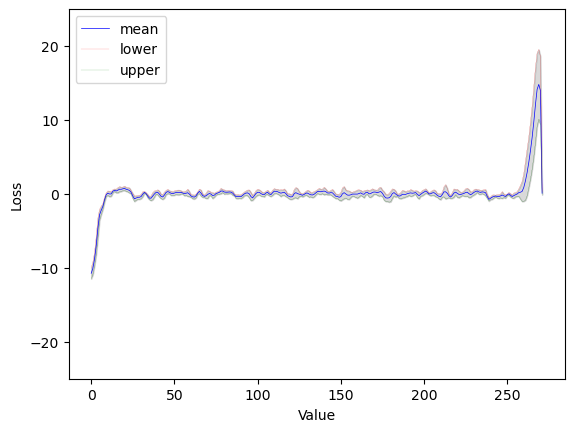

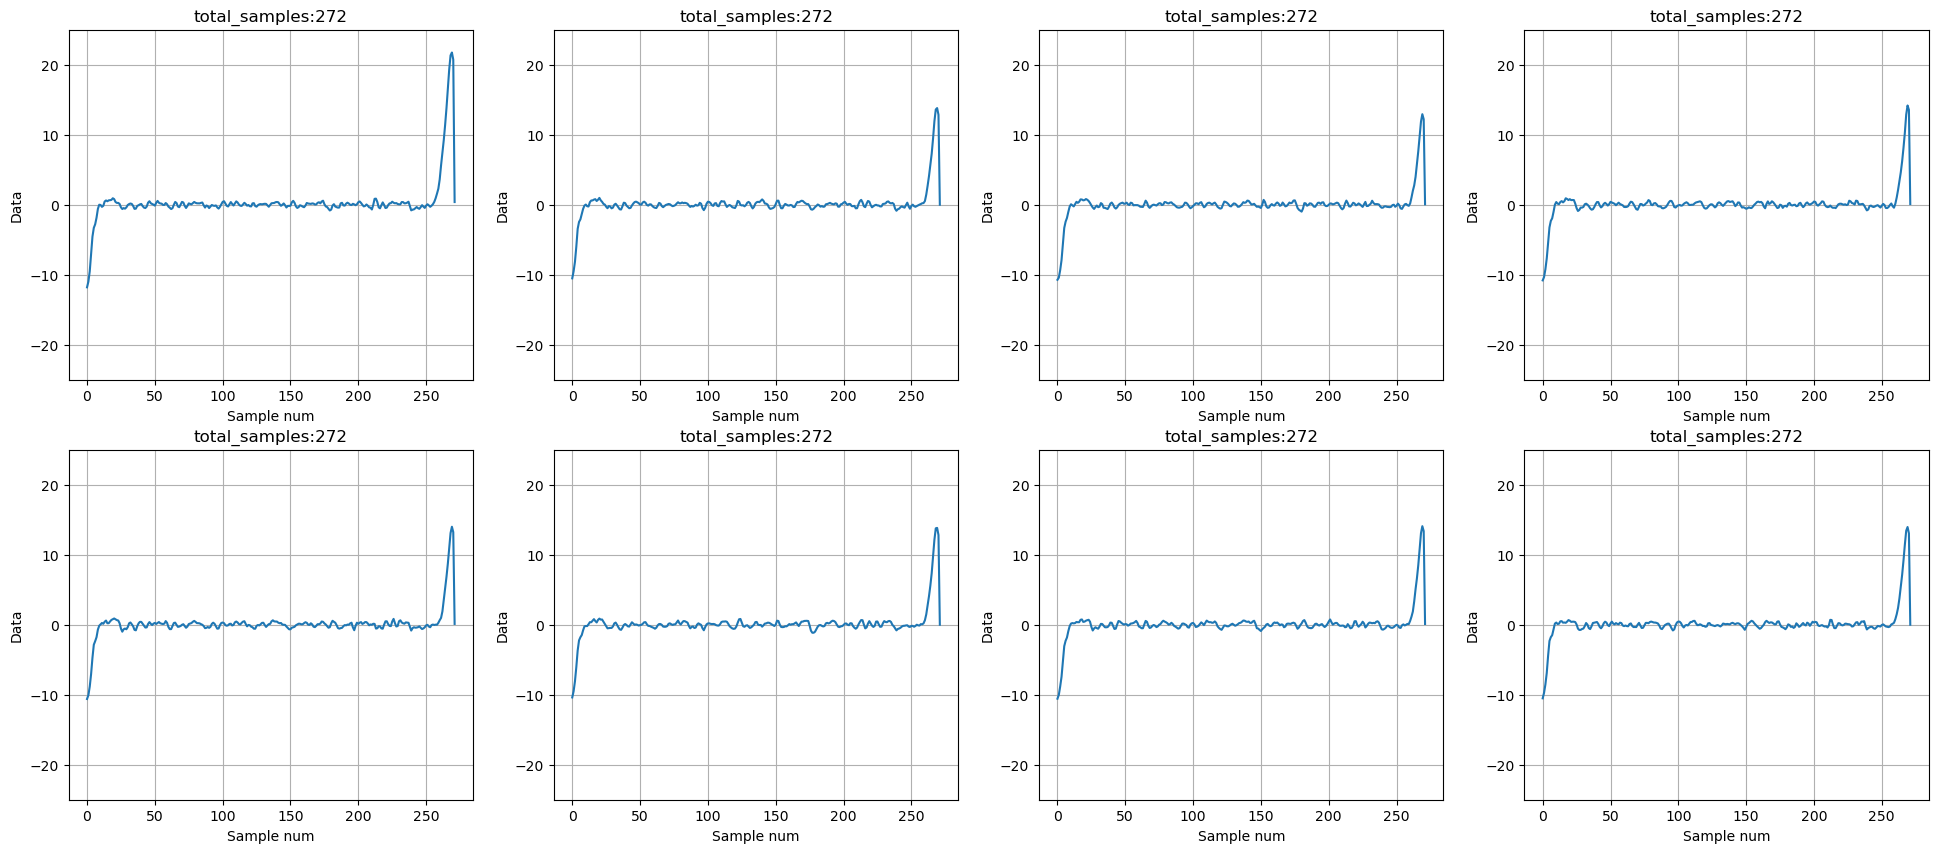

In [6]:
ref_base_dir = "C:/Users/Raiza/Downloads/convenyor_belt_verlab/arquivos/logs/logs_vale/Alinhado"
ref_files_fullpath = []
for file in os.listdir(ref_base_dir):
    if file.endswith(".csv"):
        fullpath = os.path.join(ref_base_dir, file)
        ref_files_fullpath += [fullpath]
        # print(fullpath)

ref_base_ts = []
for filepath in ref_files_fullpath[:]:
    data_df = process_file(filepath)
    acc_data_arr, gyro_data_arr, degree_data_arr = process_axis(data_df["y_data"], data_df["y_gyro"])
    # print(degree_data_arr)
    filtered_degree_data_arr = extract_z_positive_data(degree_data_arr)
    print(filtered_degree_data_arr)
    if filtered_degree_data_arr is not None:
        ref_base_ts.append(filtered_degree_data_arr)

ref_normalized_ts, max_len = normalize_timeseries(ref_base_ts, None)
ref_aligned_ts = align_timeseries(ref_normalized_ts, shift_max_size=50, is_debug=True)

ref_mean, ref_upper, ref_lower = calculate_mci_from_sequences(ref_aligned_ts, COMPARISON_CONF_INT)

plt.figure()
plt.plot(ref_mean, "-b", label="mean", linewidth=0.5)
plt.plot(ref_upper, "-r", label="lower", linewidth=0.1)
plt.plot(ref_lower, "-g", label="upper", linewidth=0.1)
# fill the area with black color, opacity 0.15
plt.fill_between(list(range(len(ref_mean))), ref_lower, ref_upper, color="k", alpha=0.15)
plt.ylim((-25, 25))
plt.xlabel("Value")
plt.ylabel("Loss")
plt.legend()

plot_axis_in_grid(ref_aligned_ts)

## Statistical Analysis - Confidence Intervals
Calculate statistical measures for the baseline condition to establish normal operation parameters.

C:/Users/Raiza/Downloads/material_raiza/material_raiza/experimento_09_04_25_LLK/Realinhamento_esquerda_em_funcionamento/192.168.1.194_20250409_143143.csv
C:/Users/Raiza/Downloads/material_raiza/material_raiza/experimento_09_04_25_LLK/Realinhamento_esquerda_em_funcionamento/192.168.1.194_20250409_143154.csv
C:/Users/Raiza/Downloads/material_raiza/material_raiza/experimento_09_04_25_LLK/Realinhamento_esquerda_em_funcionamento/192.168.1.194_20250409_143215.csv
C:/Users/Raiza/Downloads/material_raiza/material_raiza/experimento_09_04_25_LLK/Realinhamento_esquerda_em_funcionamento/192.168.1.194_20250409_143217.csv
C:/Users/Raiza/Downloads/material_raiza/material_raiza/experimento_09_04_25_LLK/Realinhamento_esquerda_em_funcionamento/192.168.1.194_20250409_143231.csv
C:/Users/Raiza/Downloads/material_raiza/material_raiza/experimento_09_04_25_LLK/Realinhamento_esquerda_em_funcionamento/192.168.1.194_20250409_143248.csv
C:/Users/Raiza/Downloads/material_raiza/material_raiza/experimento_09_04_25_

c:\Users\Raiza\anaconda3\Lib\site-packages\pybaselines\classification.py:391: ParameterWarning: there were no peak points found
  rough_baseline = _averaged_interp(self.x, y, mask, interp_half_window)
c:\Users\Raiza\anaconda3\Lib\site-packages\pybaselines\classification.py:391: ParameterWarning: there were no peak points found
  rough_baseline = _averaged_interp(self.x, y, mask, interp_half_window)
c:\Users\Raiza\anaconda3\Lib\site-packages\pybaselines\classification.py:391: ParameterWarning: there were no peak points found
  rough_baseline = _averaged_interp(self.x, y, mask, interp_half_window)


orig_len:272 new_ts_len:272 max_len:272
orig_len:271 new_ts_len:272 max_len:272
orig_len:271 new_ts_len:272 max_len:272
orig_len:271 new_ts_len:272 max_len:272
orig_len:272 new_ts_len:272 max_len:272
orig_len:271 new_ts_len:272 max_len:272
DEBUG:align_timeseries score:0.7202459218487064 best_shift_idx:0
DEBUG:align_timeseries score:1.2473590501458558 best_shift_idx:3
DEBUG:align_timeseries score:0.6879641752844432 best_shift_idx:1
DEBUG:align_timeseries score:0.19404724276581267 best_shift_idx:0
DEBUG:align_timeseries score:0.6791125639639621 best_shift_idx:1
plot_axis_in_grid: 2 4


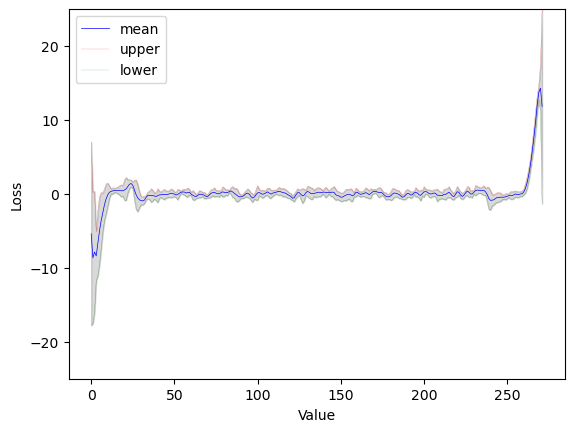

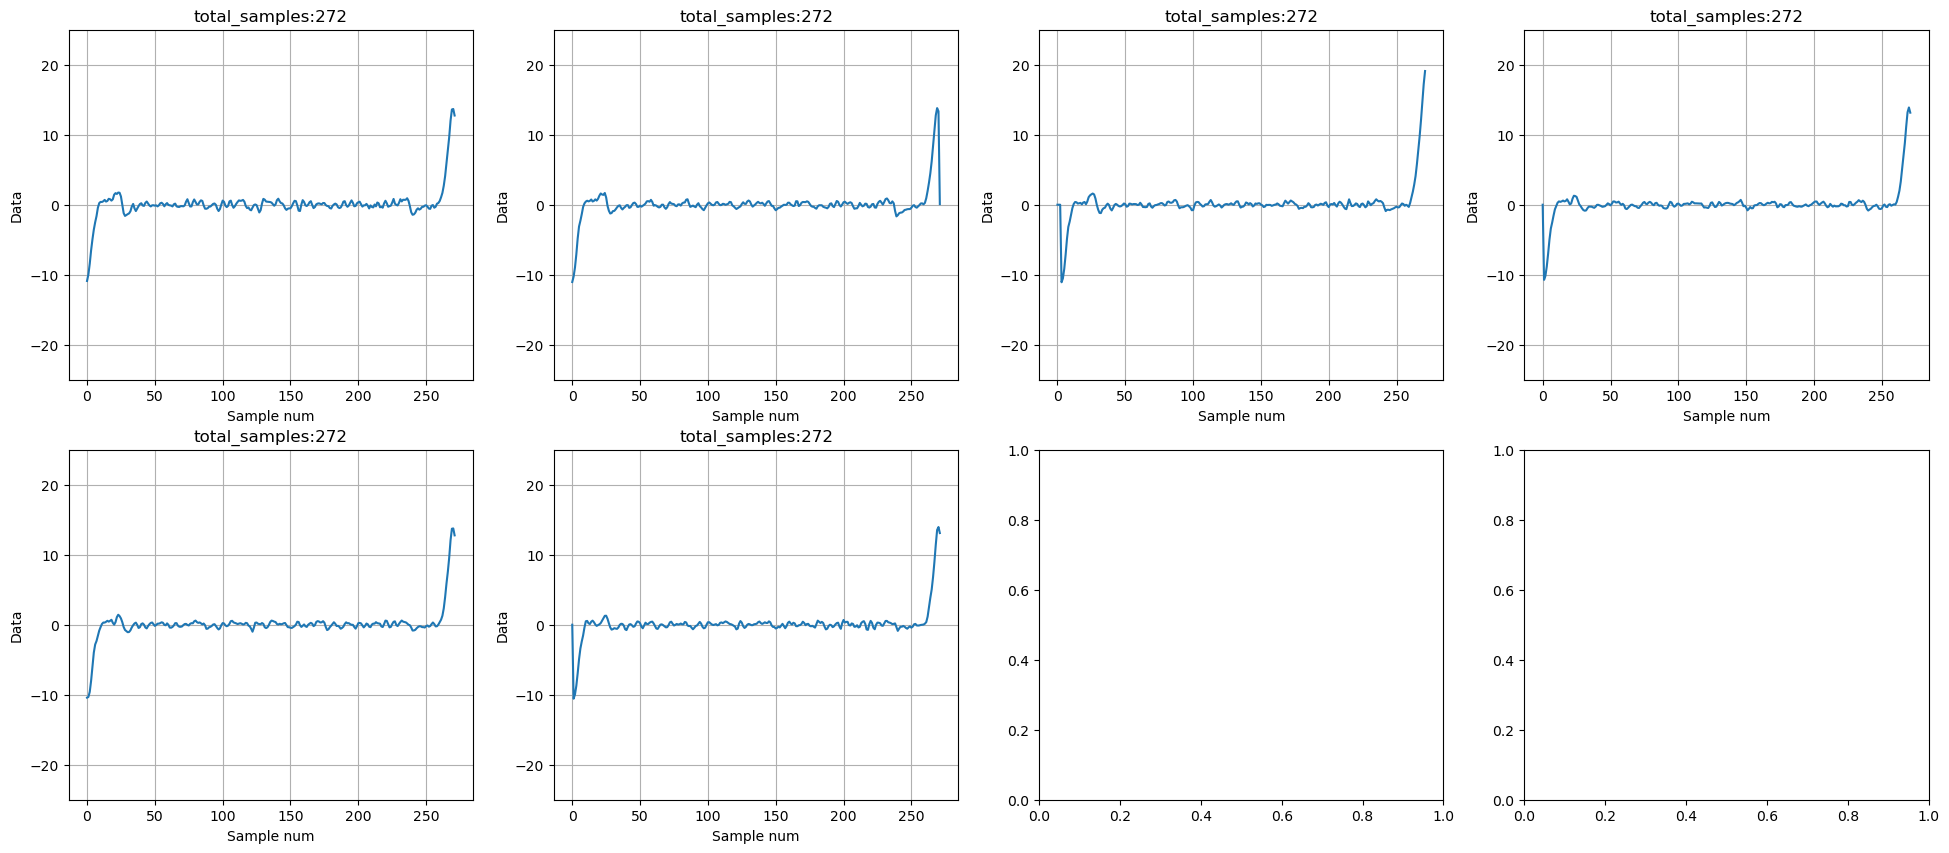

In [32]:
# Possible datasets (LLK 09/04):
# Alinhado
# Desalinhamento_direita_em_funcionamento
# Movimento_postivo_x_realinhamento_esquerda_correia
# Realinhamendo_direita_em_funcionamento
# Realinhamento_esquerda_em_funcionamento
# Rolete_travado
# Sem_dois_roletes
# Variacao_velocidade_50Hz_25Hz

test_files_fullpath = []
test_base_dir = (
    "C:/Users/Raiza/Downloads/material_raiza/material_raiza/experimento_09_04_25_LLK/Realinhamento_esquerda_em_funcionamento/"
)
for file in os.listdir(test_base_dir):
    if file.endswith(".csv"):
        fullpath = os.path.join(test_base_dir, file)
        test_files_fullpath += [fullpath]
        print(fullpath)

test_base_ts = []
for filepath in test_files_fullpath[:]:
    data_df = process_file(filepath)
    acc_data_arr, gyro_data_arr, degree_data_arr = process_axis(data_df["y_data"], data_df["y_gyro"])
    filtered_degree_data_arr = extract_z_positive_data(degree_data_arr)
    if filtered_degree_data_arr is not None:
        test_base_ts.append(filtered_degree_data_arr)

test_normalized_ts, max_len = normalize_timeseries(test_base_ts, None)
test_aligned_ts = align_timeseries(test_normalized_ts, shift_max_size=50, is_debug=True)

test_mean, test_upper, test_lower = calculate_mci_from_sequences(test_aligned_ts, COMPARISON_CONF_INT)

plt.figure()
plt.plot(test_mean, "-b", label="mean", linewidth=0.5)
plt.plot(test_upper, "-r", label="upper", linewidth=0.1)
plt.plot(test_lower, "-g", label="lower", linewidth=0.1)
# fill the area with black color, opacity 0.15
plt.fill_between(list(range(len(test_mean))), test_upper, test_lower, color="k", alpha=0.15)

plt.xlabel("Value")
plt.ylabel("Loss")
plt.ylim((-25, 25))
plt.legend()

plot_axis_in_grid(test_aligned_ts)

C:\Users\Raiza\AppData\Local\Temp\ipykernel_7140\3237451778.py:9: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "-r" (-> linestyle='-'). The keyword argument will take precedence.
  plt.plot(test_mean, "-r", label="test avg", linestyle="--", linewidth=1)


Text(0.5, 1.0, 'Analysis: Rolete_travado')

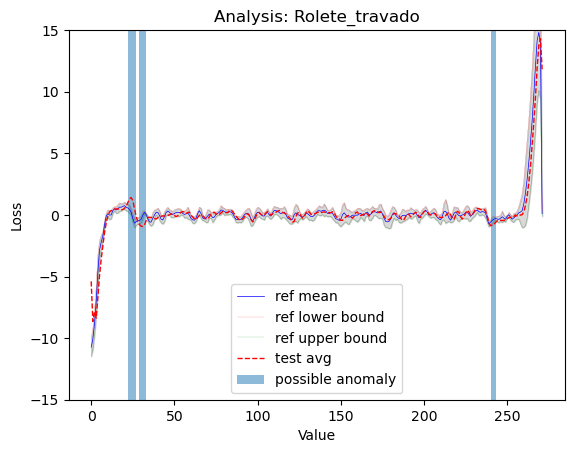

In [33]:
# plot diferences

plt.figure()
l1 = plt.plot(ref_mean, "-b", label="ref mean", linewidth=0.5)
l2 = plt.plot(ref_upper, "-r", label="ref lower bound", linewidth=0.1)
l3 = plt.plot(ref_lower, "-g", label="ref upper bound", linewidth=0.1)
l4 = plt.fill_between(list(range(len(ref_mean))), ref_lower, ref_upper, color="k", alpha=0.15)

plt.plot(test_mean, "-r", label="test avg", linestyle="--", linewidth=1)

plt.ylim((-15, 15))
plt.xlabel("Value")
plt.ylabel("Loss")

results = []
current_subarray = []

border_offset_to_ignore = int(len(ref_mean) * 0.05)  # ignore the 5% borders (~10 percent of the data)
for idx in range(border_offset_to_ignore, len(ref_mean) - border_offset_to_ignore, 1):
    test_v = test_mean[idx]
    ref_up = ref_upper[idx]
    ref_low = ref_lower[idx]
    if test_v > ref_up or test_v < ref_low:
        current_subarray.append(idx)
    else:
        if current_subarray and len(current_subarray) > 3:
            results.append(current_subarray)
        current_subarray = []

if current_subarray:
    results.append(current_subarray)

if results:
    plt.axvspan(results[0][0], results[0][-1], alpha=0.5, label="possible anomaly")
    for subarr in results[1:]:
        plt.axvspan(subarr[0], subarr[-1], alpha=0.5)

plt.legend()
plt.title("Analysis: Rolete_travado")
# plt.savefig("Rolete_travado.png")